In [1]:
import pandas as pd
import numpy as np

%matplotlib inline

#Лабораторная работа №1

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [2]:
df1 = pd.read_csv('Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', encoding='latin-1')
df2 = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', encoding='latin-1')
df3 = pd.read_csv('Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', encoding='latin-1')

df = pd.concat([df1, df2, df3], ignore_index=True)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 682578 entries, 0 to 682577
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             682578 non-null  int64  
 1    Flow Duration                682578 non-null  int64  
 2    Total Fwd Packets            682578 non-null  int64  
 3    Total Backward Packets       682578 non-null  int64  
 4   Total Length of Fwd Packets   682578 non-null  int64  
 5    Total Length of Bwd Packets  682578 non-null  int64  
 6    Fwd Packet Length Max        682578 non-null  int64  
 7    Fwd Packet Length Min        682578 non-null  int64  
 8    Fwd Packet Length Mean       682578 non-null  float64
 9    Fwd Packet Length Std        682578 non-null  float64
 10  Bwd Packet Length Max         682578 non-null  int64  
 11   Bwd Packet Length Min        682578 non-null  int64  
 12   Bwd Packet Length Mean       682578 non-null  float64


In [4]:
df.head() #проверяем корректность отображения

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,389,113095465,48,24,9668,10012,403,0,201.416667,203.548293,923,316,417.166667,231.080951,1.740123e+02,0.636630,1.592894e+06,4.597265e+06,16500000,3,113000000,2.406286e+06,5.491986e+06,16500000,3,113000000,4917177.522,7.084368e+06,16500000,3,1,0,0,0,1536,768,0.424420,0.212210,0,923,275.109589,233.833248,54677.98782,0,1,0,0,1,0,0,0,0,278.930556,201.416667,417.166667,1536,0,0,0,0,0,0,48,9668,24,10012,571,2079,23,32,203985.500,5.758373e+05,1629110,379,13800000.0,4.277541e+06,16500000,6737603,BENIGN
1,389,113473706,68,40,11364,12718,403,0,167.117647,171.919413,1139,126,317.950000,208.261294,2.122254e+02,0.951762,1.060502e+06,3.813685e+06,16500000,2,113000000,1.693637e+06,4.719143e+06,16500000,2,113000000,2908399.744,5.922355e+06,16500000,3,1,0,0,0,2176,1280,0.599258,0.352505,0,1139,224.633027,198.999612,39600.84557,0,1,0,0,1,0,0,0,0,226.712963,167.117647,317.950000,2176,0,0,0,0,0,0,68,11364,40,12718,390,2081,39,32,178326.875,5.034269e+05,1424245,325,13800000.0,4.229413e+06,16500000,6945512,BENIGN
2,0,119945515,150,0,0,0,0,0,0.000000,0.000000,0,0,0.000000,0.000000,0.000000e+00,1.250568,8.050035e+05,5.277837e+06,60100000,0,120000000,8.050035e+05,5.277837e+06,60100000,0,0,0.000,0.000000e+00,0,0,0,0,0,0,0,0,1.250568,0.000000,0,0,0.000000,0.000000,0.00000,0,0,0,0,0,0,0,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0,150,0,0,0,-1,-1,0,0,6909777.333,1.170000e+07,20400000,6,24400000.0,2.430000e+07,60100000,5702188,BENIGN
3,443,60261928,9,7,2330,4221,1093,0,258.888889,409.702161,1460,0,603.000000,653.594166,1.087088e+02,0.265508,4.017462e+06,1.550000e+07,60000000,1,60300000,7.532741e+06,2.120000e+07,60000000,311,211947,35324.500,2.750433e+04,57109,48,0,0,0,0,192,152,0.149348,0.116160,0,1460,385.352941,532.094087,283124.11760,0,0,0,1,0,0,0,0,0,409.437500,258.888889,603.000000,192,0,0,0,0,0,0,9,2330,7,4221,8192,513,8,20,0.000,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN
4,53,269,2,2,102,322,51,51,51.000000,0.000000,161,161,161.000000,0.000000,1.576208e+06,14869.888480,8.966667e+01,1.483790e+02,261,4,4,4.000000e+00,0.000000e+00,4,4,4,4.000,0.000000e+00,4,4,0,0,0,0,64,64,7434.944238,7434.944238,51,161,95.000000,60.249481,3630.00000,0,0,0,0,0,0,0,0,1,118.750000,51.000000,161.000000,64,0,0,0,0,0,0,2,102,2,322,-1,-1,1,32,0.000,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN


In [5]:
df.describe(include='all') #статистика

C:\Users\yangm\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\yangm\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
count,682578.00000,6.825780e+05,682578.000000,682578.000000,6.825780e+05,6.825780e+05,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,6.825390e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,682578.000000,682578.0,682578.0,682578.0,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,682578.000000,682578.000000,682578.000000,682578.000000,6.825780e+05,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,682578.0,682578.000000,682578.000000,682578.000000,682578.000000,682578.000000,6.825780e+05,682578.0,682578.0,682578.0,682578.0,682578.0,682578.0,682578.000000,6.825780e+05,682578.000000,6.825780e+05,682578.000000,682578.000000,682578.000000,682578.000000,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,6.825780e+05,682578
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BENIGN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,393441
mean,8284.05987,1.073992e+07,6.844917,7.488039,5.476798e+02,1.105234e+04,253.990678,19.231081,76.681420,93.185085,1082.936349,30.424596,366.581812,460.820995,inf,inf,9.044771e+05,2.085717e+06,6.312903e+06,4.987303e+04,1.033907e+07,1.669404e+06,2.225050e+06,6.098992e+06,5.647671e+05,7.063675e+06,1.117987e+06,9.133274e+05,3.054341e+06,5.956026e+05,0.030755,0.0,0.0,0.0,1.621039e+02,1.718373e+02,3.361449e+04,1.097260e+04,12.437283,1262.877459,215.344559,416.787638,9.557507e+05,0.007237,0.030755,0.000152,0.452715,0.286996,0.093597,0.0,0.000152,0.857807,241.681818,76.681420,366.581812,1.621039e+02,0.0,0.0,0.0,0.0,0.0,0.0,6.844917,5.476798e+02,7.488039,1.105218e+04,7639.491205,1285.715838,4.797077,25

In [6]:
print(df.isna().mean()) 

 Destination Port               0.000000
 Flow Duration                  0.000000
 Total Fwd Packets              0.000000
 Total Backward Packets         0.000000
Total Length of Fwd Packets     0.000000
 Total Length of Bwd Packets    0.000000
 Fwd Packet Length Max          0.000000
 Fwd Packet Length Min          0.000000
 Fwd Packet Length Mean         0.000000
 Fwd Packet Length Std          0.000000
Bwd Packet Length Max           0.000000
 Bwd Packet Length Min          0.000000
 Bwd Packet Length Mean         0.000000
 Bwd Packet Length Std          0.000000
Flow Bytes/s                    0.000057
 Flow Packets/s                 0.000000
 Flow IAT Mean                  0.000000
 Flow IAT Std                   0.000000
 Flow IAT Max                   0.000000
 Flow IAT Min                   0.000000
Fwd IAT Total                   0.000000
 Fwd IAT Mean                   0.000000
 Fwd IAT Std                    0.000000
 Fwd IAT Max                    0.000000
 Fwd IAT Min    

In [7]:
df.isna().sum() #Flow Bytes/s - 39 пропусков

 Destination Port                0
 Flow Duration                   0
 Total Fwd Packets               0
 Total Backward Packets          0
Total Length of Fwd Packets      0
 Total Length of Bwd Packets     0
 Fwd Packet Length Max           0
 Fwd Packet Length Min           0
 Fwd Packet Length Mean          0
 Fwd Packet Length Std           0
Bwd Packet Length Max            0
 Bwd Packet Length Min           0
 Bwd Packet Length Mean          0
 Bwd Packet Length Std           0
Flow Bytes/s                    39
 Flow Packets/s                  0
 Flow IAT Mean                   0
 Flow IAT Std                    0
 Flow IAT Max                    0
 Flow IAT Min                    0
Fwd IAT Total                    0
 Fwd IAT Mean                    0
 Fwd IAT Std                     0
 Fwd IAT Max                     0
 Fwd IAT Min                     0
Bwd IAT Total                    0
 Bwd IAT Mean                    0
 Bwd IAT Std                     0
 Bwd IAT Max        

In [8]:
proc = df.isna().sum().sum() / df.size
print(round(100*proc,1), '%', sep='') #Количество пропусков незначительное

0.0%


In [9]:
df = df.dropna() #Удаляем строки с пустыми ячейками
df.isna().sum()

 Destination Port               0
 Flow Duration                  0
 Total Fwd Packets              0
 Total Backward Packets         0
Total Length of Fwd Packets     0
 Total Length of Bwd Packets    0
 Fwd Packet Length Max          0
 Fwd Packet Length Min          0
 Fwd Packet Length Mean         0
 Fwd Packet Length Std          0
Bwd Packet Length Max           0
 Bwd Packet Length Min          0
 Bwd Packet Length Mean         0
 Bwd Packet Length Std          0
Flow Bytes/s                    0
 Flow Packets/s                 0
 Flow IAT Mean                  0
 Flow IAT Std                   0
 Flow IAT Max                   0
 Flow IAT Min                   0
Fwd IAT Total                   0
 Fwd IAT Mean                   0
 Fwd IAT Std                    0
 Fwd IAT Max                    0
 Fwd IAT Min                    0
Bwd IAT Total                   0
 Bwd IAT Mean                   0
 Bwd IAT Std                    0
 Bwd IAT Max                    0
 Bwd IAT Min  

In [10]:
print(df.columns.tolist()) #как называются колонки, в названиях есть пробелы

[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

In [11]:
#Убрать пробелы в названиях, написать более ясно тип атаки
df.columns = df.columns.str.strip() #убираем пробелы в названиях
df = df.rename(columns={
    'Destination Port': 'dst_port',
    'Total Fwd Packets': 'fwd_packets',
    'Total Backward Packets': 'bwd_packets',
    'Flow Duration': 'flow_duration',
    'Total Length of Fwd Packets': 'length_fwd_packet',
    'Total Length of Bwd Packets': 'length_bwd_packet',
    'Label': 'attack_type'
})

df['total_bytes'] = df['length_fwd_packet'] + df['length_bwd_packet'] # Новый столбец

In [12]:
print(df['attack_type'].unique()) #Какие уникальные значения есть в attack_type до исправлений и группировки

<StringArray>
[                      'BENIGN',   'Web Attack ï¿½ Brute Force',
           'Web Attack ï¿½ XSS', 'Web Attack ï¿½ Sql Injection',
                         'DDoS',                     'PortScan']
Length: 6, dtype: str


In [13]:
import re
df['attack_type_new'] = df['attack_type'].apply(lambda x: re.sub(r'Web Attack ï¿½ ', '', x)) #Убираем Web Attack ï¿½, после исправления
print(df['attack_type_new'].unique())

<StringArray>
['BENIGN', 'Brute Force', 'XSS', 'Sql Injection', 'DDoS', 'PortScan']
Length: 6, dtype: str


In [14]:
#Проверка сбалансированности классов целевого признака

class_counts = df['attack_type_new'].value_counts()
class_props = df['attack_type_new'].value_counts(normalize=True) * 100
distribution = pd.DataFrame({'Класс': class_counts.index, 'Количество': class_counts.values, 'Доля (%)': class_props.values.round(4)})
print("Распределение классов до группировки:")
print(distribution.to_string(index=False))

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nКоэффициент дисбаланса (max/min): {imbalance_ratio:.1f} : 1")

Распределение классов до группировки:
        Класс  Количество  Доля (%)
       BENIGN      393402   57.6380
     PortScan      158930   23.2851
         DDoS      128027   18.7575
  Brute Force        1507    0.2208
          XSS         652    0.0955
Sql Injection          21    0.0031

Коэффициент дисбаланса (max/min): 18733.4 : 1


(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'BENIGN'),
  Text(1, 0, 'PortScan'),
  Text(2, 0, 'DDoS'),
  Text(3, 0, 'Brute Force'),
  Text(4, 0, 'XSS'),
  Text(5, 0, 'Sql Injection')])

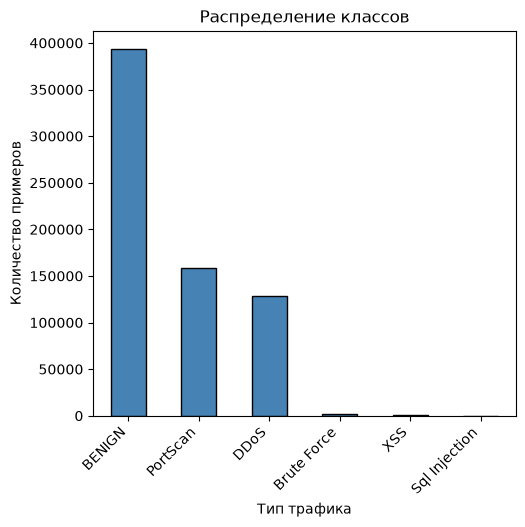

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
class_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Распределение классов')
plt.xlabel('Тип трафика')
plt.ylabel('Количество примеров')
plt.xticks(rotation=45, ha='right')

<StringArray>
['Normal', 'WebAttack', 'DDoS', 'PortScan']
Length: 4, dtype: str
Распределение классов после группировки:
    Класс  Количество  Доля (%)
   Normal      393402   57.6380
 PortScan      158930   23.2851
     DDoS      128027   18.7575
WebAttack        2180    0.3194

Коэффициент дисбаланса (max/min): 180.5 : 1


(array([0, 1, 2, 3]),
 [Text(0, 0, 'Normal'),
  Text(1, 0, 'PortScan'),
  Text(2, 0, 'DDoS'),
  Text(3, 0, 'WebAttack')])

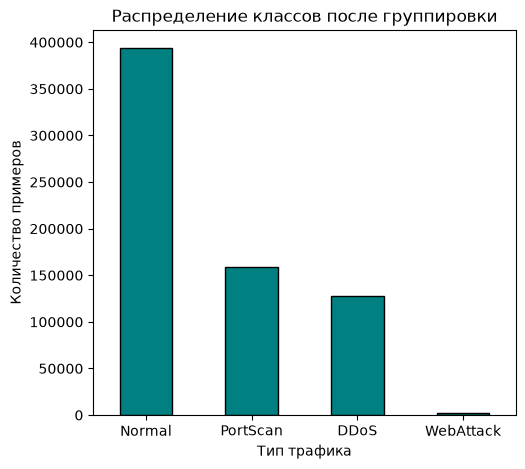

In [16]:
def group_attack(label):
    if label in ['Brute Force', 'XSS', 'Sql Injection']: #Группируем web attack так как по отдельности их мало
        return 'WebAttack'
    if label.upper() == 'BENIGN': #Переименовываем, чтобы было понятно
        return 'Normal'
    return label

df['attack_group'] = df['attack_type_new'].apply(group_attack)

#Что получилось после группировки
print(df['attack_group'].unique())

class_counts_after = df['attack_group'].value_counts()
class_props_after = df['attack_group'].value_counts(normalize=True) * 100

distribution_after = pd.DataFrame({'Класс': class_counts_after.index, 'Количество': class_counts_after.values, 'Доля (%)': class_props_after.values.round(4)})
print("Распределение классов после группировки:")
print(distribution_after.to_string(index=False))

imbalance_ratio_after = class_counts_after.max() / class_counts_after.min()
print(f"\nКоэффициент дисбаланса (max/min): {imbalance_ratio_after:.1f} : 1")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
class_counts_after.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Распределение классов после группировки')
plt.xlabel('Тип трафика')
plt.ylabel('Количество примеров')
plt.xticks(rotation=0)

In [17]:
#Отношения
df['bytes_ratio'] = df['length_fwd_packet'] / (df['length_bwd_packet'] + 1)
df['packets_ratio'] = df['fwd_packets'] / (df['bwd_packets'] + 1)
df['bytes_per_packet_fwd'] = df['length_fwd_packet'] / (df['fwd_packets'] + 1)
df['bytes_per_packet_bwd'] = df['length_bwd_packet'] / (df['bwd_packets'] + 1)

#Суммы и разности
df['total_bytes'] = df['length_fwd_packet'] + df['length_bwd_packet']
df['total_packets'] = df['fwd_packets'] + df['bwd_packets']
df['bytes_diff'] = df['length_fwd_packet'] - df['length_bwd_packet']

#Логарифмирование
import numpy as np
df['log_duration'] = np.log1p(df['flow_duration'].clip(lower=0))
df['log_bytes_per_sec'] = np.log1p(df['Flow Bytes/s'].clip(lower=0))

In [18]:
df_numeric = df.select_dtypes(include=[np.number]) #Датафрейм, где только значения с числами

In [19]:
for feature in df_numeric.columns:
    if df_numeric[feature].max()>10*df_numeric[feature].median() and df_numeric[feature].max()>10:
        df[feature] = np.where(df[feature]<df[feature].quantile(0.95), df[feature], df[feature].quantile(0.95)) #Убираем сильное отклонение

In [20]:
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.describe(include='all')

,dst_port,flow_duration,fwd_packets,bwd_packets,length_fwd_packet,length_bwd_packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,total_bytes,bytes_ratio,packets_ratio,bytes_per_packet_fwd,bytes_per_packet_bwd,total_packets,bytes_diff,log_duration,log_bytes_per_sec
count,682539.000000,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,682539.000000,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,682539.000000,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,682539.000000,682539.000000,682539.0,682539.0,682539.0,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.0,682539.000000,682539.00000,682539.000000,682539.000000,682539.000000,682539.000000,682539.0,682539.0,682539.0,682539.0,682539.0,682539.0,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,682539.000000,6.825390e+05,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,682539.000000,682539.000000
mean,8070.841458,9.798017e+06,3.388765,2.873935,195.053078,2014.308878,92.116650,12.073440,27.370763,25.118084,966.902937,27.453737,348.308763,401.901331,2.355495e+05,1.941766e+04,6.777104e+05,1.725348e+06,5.356388e+06,3659.793525,9.371560e+06,1.056656e+06,1.708534e+06,5.085530e+06,430.981681,5.448931e+06,4.539460e+05,4.541358e+05,1.135494e+06,25.719471,0.030757,0.0,0.0,0.0,82.651060,70.034181,10052.206037,7011.936794,11.744879,1195.573805,211.140979,386.344276,7.637630e+05,0.007238,0.030757,0.000152,0.452740,0.286955,0.093595,0.0,0.000152,0.76881,236.157558,27.370763,348.308763,82.651060,0.0,0.0,0.0,0.0,0.0,0.0,3.388765,195.053078,2.873935,2014.308878,7137.614352,126.125802,1.802263,25.692586,17656.100227,647.497723,37274.785594,8166.338646,3.694531e+06,4147.563634,4.900084e+06,1.706070e+06,2424.156765,4.184922,1.034859,20.818716,290.820541,6.329433,-1.081963e+04,9.623962,8.711325
std,17037.936992,2.515330e+07,3.642646,3.515569,446.591377,4080.942337,199.455111,17.861846,37.291541,63.608769,2091.559590,45.687871,710.633433,934.931205,6.090879e+05,3.496380e+04,1.461203e+06,4.288775e+06,1.463006e+07,11648.748441,2.495230e+07,2.630789e+06,4.752416e+06,1.470323e+07,1577.623073,1.783462e+07,1.361635e+06,1.253501e+06,2.952858e+06,59.712638,0.172659,0.0,0.0,0.0,85.290594,90.703662,15727.681228,10309.286259,17.566411,2432.907045,388.576758,783.901783,1.900576e+06,0.084766,0.172659,0.012343,0.497762,0.452341,0.291264,0.0,0.012343,0.55

In [21]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

top_10_ports = df['dst_port'].value_counts().head(10).index.tolist()
df['dst_port_top'] = df['dst_port'].apply(lambda x: f'port_{x}' if x in top_10_ports else 'other')

def port_range(port):
    port = int(port)
    if port <= 1023: return 'well_known'
    if port <= 49151: return 'registered'
    return 'ephemeral'
df['dst_port_range'] = df['dst_port'].apply(port_range)

X = df.drop(columns=['attack_group', 'attack_type_new', 'attack_type', 'dst_port']) #Признаки
y = df['attack_group'] #Целевая переменная

In [22]:
numeric_cols = X.select_dtypes(include=['number']).columns

constant_cols = [col for col in numeric_cols if X[col].std() == 0]
print("Константные признаки:", constant_cols)
X = X.drop(columns=constant_cols)

Константные признаки: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [23]:
X.describe(include='all')

,flow_duration,fwd_packets,bwd_packets,length_fwd_packet,length_bwd_packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,total_bytes,bytes_ratio,packets_ratio,bytes_per_packet_fwd,bytes_per_packet_bwd,total_packets,bytes_diff,log_duration,log_bytes_per_sec,dst_port_top,dst_port_range
count,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,682539.000000,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,682539.000000,6.825390e+05,6.825390e+05,6.825390e+05,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.00000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,682539.000000,6.825390e+05,6.825390e+05,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,682539.000000,6.825390e+05,682539.000000,682539.000000,682539,682539
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,other,well_known
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,218093,455535
mean,9.798017e+06,3.388765,2.873935,195.053078,2014.308878,92.116650,12.073440,27.370763,25.118084,966.902937,27.453737,348.308763,401.901331,2.355495e+05,1.941766e+04,6.777104e+05,1.725348e+06,5.356388e+06,3659.793525,9.371560e+06,1.056656e+06,1.708534e+06,5.085530e+06,430.981681,5.448931e+06,4.539460e+05,4.541358e+05,1.135494e+06,25.719471,0.030757,82.651060,70.034181,10052.206037,7011.936794,11.744879,1195.573805,211.140979,386.344276,7.637630e+05,0.007238,0.030757,0.000152,0.452740,0.286955,0.093595,0.000152,0.76881,236.157558,27.370763,348.308763,82.651060,3.388765,195.053078,2.873935,2014.308878,7137.614352,126.125802,1.802263,25.692586,17656.100227,647.497723,37274.785594,8166.338646,3.694531e+06,4147.563634,4.900

In [24]:
df_cat = X.select_dtypes(exclude=[np.number])
original_feature_names = list(X.columns)

categorical_cols = X.select_dtypes(include=['object', 'str']).columns.tolist() #Определяем категориальные признаки

print("Категориальные признаки:", categorical_cols)

Категориальные признаки: ['dst_port_top', 'dst_port_range']


In [25]:
#Разбиение на X и y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y) #Разделение на признаки и целевую переменную

In [26]:
if categorical_cols: #Кодируем
    ct = ColumnTransformer(transformers=[('onehot', OneHotEncoder(handle_unknown='ignore'), categorical_cols)], remainder='passthrough')
    #ignore - что делать, с категорией, которой не было в обучающих данных
    X_train_enc = ct.fit_transform(X_train) #Изучает, какие есть уникальные категории и присваивает номера
    X_test_enc  = ct.transform(X_test) #Применяет правила train на test
else:
    X_train_enc, X_test_enc = X_train.values, X_test.values #Если категорианльных признаков нет, то берем значения, как есть. .values - делает массив

le = LabelEncoder() #кодируем целевые переменные
y_train_enc = le.fit_transform(y_train) #Находит все уникальные значения в y_train и запоминает их
y_test_enc  = le.transform(y_test)

In [27]:
print(dict(zip(le.classes_, le.transform(le.classes_)))) #zip - создает пары, из значений и чисел после кодирования, dict - показывает соответствие
print("X_train до кодирования:", X_train.shape)
print("X_train после кодирования:", X_train_enc.shape)

{'DDoS': np.int64(0), 'Normal': np.int64(1), 'PortScan': np.int64(2), 'WebAttack': np.int64(3)}
X_train до кодирования: (546031, 78)
X_train после кодирования: (546031, 90)


In [28]:
if categorical_cols:
    ohe_names = ct.named_transformers_['onehot'].get_feature_names_out(categorical_cols) #Столбцы, созданные one-hot encoding
    numeric_cols = [c for c in X.columns if c not in categorical_cols] #Числовые столбцы
    feature_names = list(ohe_names) + numeric_cols #Итоговый список всех имен
else:
    feature_names = list(X.columns)

print("Количество имён:", len(feature_names))
print("Количество столбцов:", X_train_enc.shape[1])
print(feature_names)

Количество имён: 90
Количество столбцов: 90
['dst_port_top_other', 'dst_port_top_port_123.0', 'dst_port_top_port_137.0', 'dst_port_top_port_21.0', 'dst_port_top_port_22.0', 'dst_port_top_port_389.0', 'dst_port_top_port_443.0', 'dst_port_top_port_53.0', 'dst_port_top_port_55004.0', 'dst_port_top_port_80.0', 'dst_port_top_port_8080.0', 'dst_port_range_ephemeral', 'dst_port_range_registered', 'dst_port_range_well_known', 'flow_duration', 'fwd_packets', 'bwd_packets', 'length_fwd_packet', 'length_bwd_packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Len

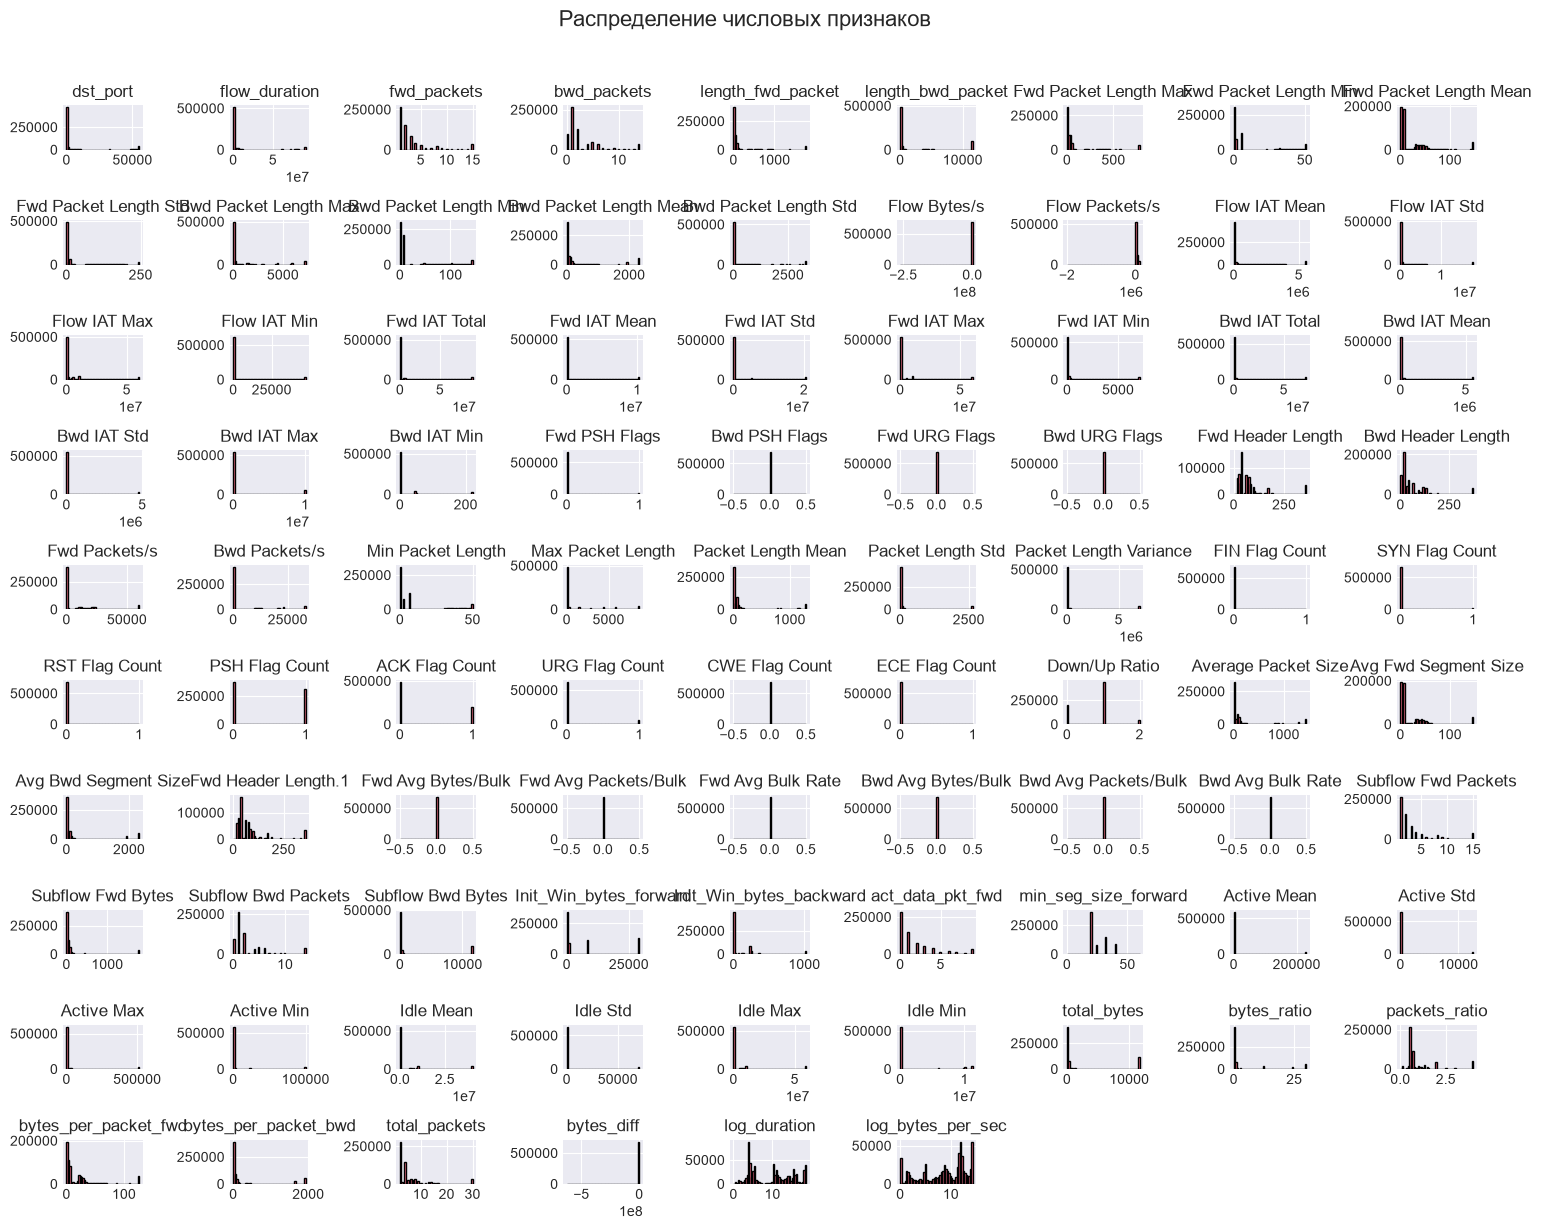

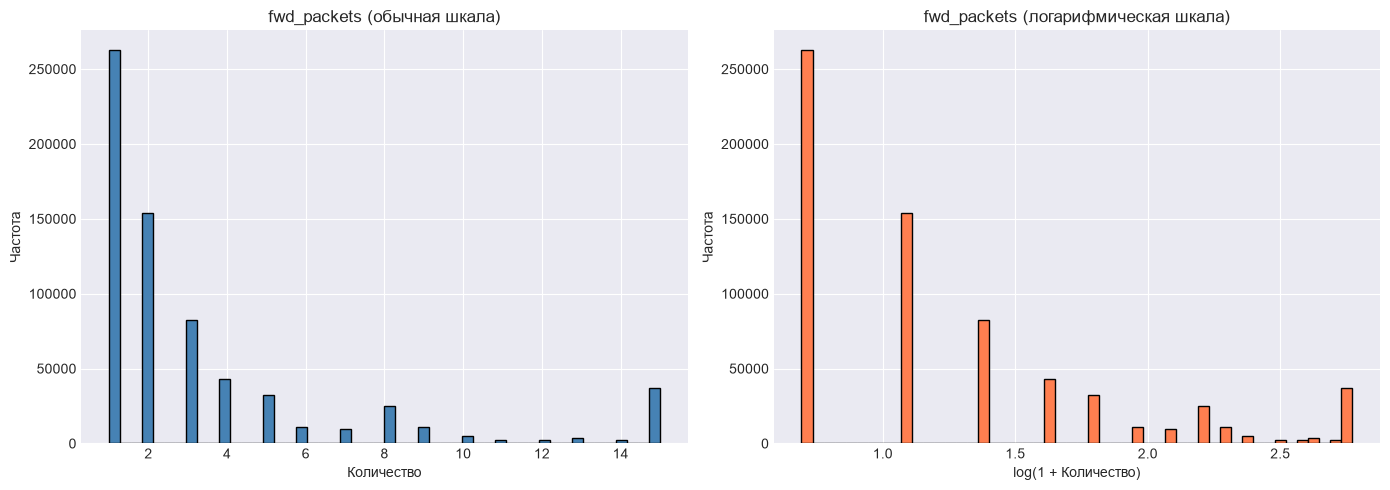

In [29]:
import matplotlib.pyplot as plt #Для визуализации данных
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

#1. Гистограмма распределений
df.hist(figsize=(15, 12), bins=50, edgecolor='black')
plt.suptitle('Распределение числовых признаков', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Гистограмма для отдельного значения
axes[0].hist(df['fwd_packets'], bins=50, color='steelblue', edgecolor='black')
axes[0].set_title('fwd_packets (обычная шкала)')
axes[0].set_xlabel('Количество')
axes[0].set_ylabel('Частота')

axes[1].hist(np.log1p(df['fwd_packets']), bins=50, color='coral', edgecolor='black')
axes[1].set_title('fwd_packets (логарифмическая шкала)')
axes[1].set_xlabel('log(1 + Количество)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

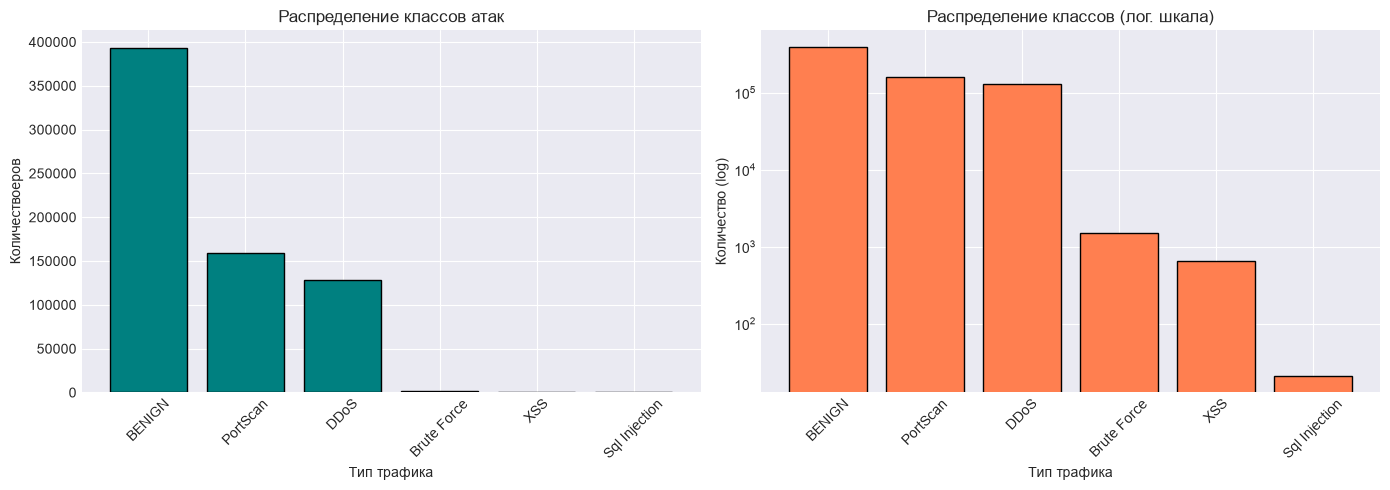

attack_type_new
BENIGN           393402
PortScan         158930
DDoS             128027
Brute Force        1507
XSS                 652
Sql Injection        21
Name: count, dtype: int64

Доли классов:
attack_type_new
BENIGN           0.576380
PortScan         0.232851
DDoS             0.187575
Brute Force      0.002208
XSS              0.000955
Sql Injection    0.000031
Name: proportion, dtype: float64


In [30]:
#2. Диаграмма распределения классов
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_counts = df['attack_type_new'].value_counts() #количество уникальных значений attack_type_new
axes[0].bar(class_counts.index, class_counts.values, color='teal', edgecolor='black') #Строим график, где x - тип атаки, y - количество атак
axes[0].set_title('Распределение классов атак')
axes[0].set_xlabel('Тип трафика')
axes[0].set_ylabel('Количествоеров')
axes[0].tick_params(axis='x', rotation=45)

#Логарифмическая шкала
axes[1].bar(class_counts.index, class_counts.values, color='coral', edgecolor='black')
axes[1].set_yscale('log')
axes[1].set_title('Распределение классов (лог. шкала)')
axes[1].set_xlabel('Тип трафика')
axes[1].set_ylabel('Количество (log)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(class_counts)
print("\nДоли классов:")
print(df['attack_type_new'].value_counts(normalize=True)) #Доля каждого класса

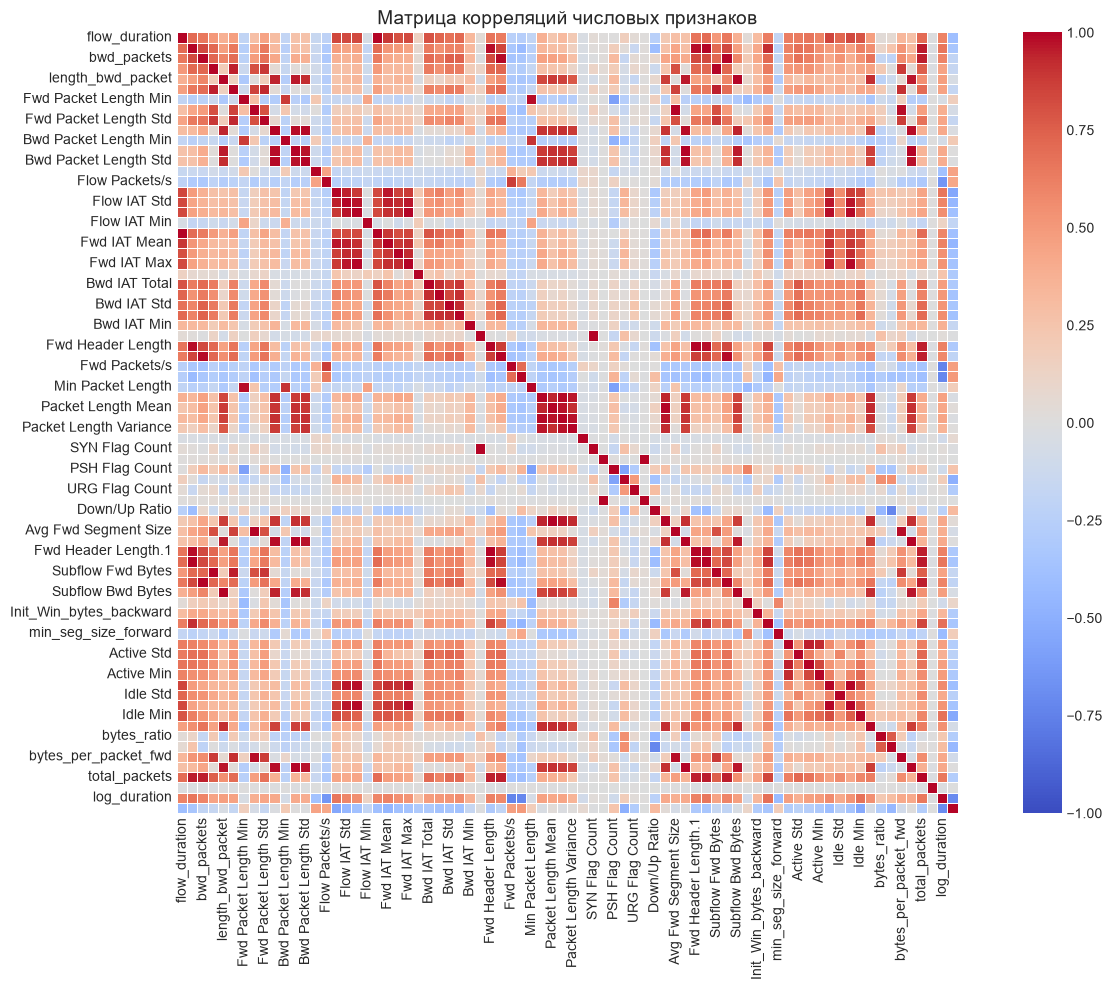

Сильно коррелирующие пары признаков:
flow_duration <-> Fwd IAT Total: r = 0.997
fwd_packets <-> Fwd Header Length: r = 0.979
fwd_packets <-> Fwd Header Length.1: r = 0.979
fwd_packets <-> Subflow Fwd Packets: r = 1.000
fwd_packets <-> total_packets: r = 0.961
bwd_packets <-> Bwd Header Length: r = 0.985
bwd_packets <-> Subflow Bwd Packets: r = 1.000
bwd_packets <-> total_packets: r = 0.951
length_fwd_packet <-> Subflow Fwd Bytes: r = 1.000
length_bwd_packet <-> Bwd Packet Length Mean: r = 0.954
length_bwd_packet <-> Avg Bwd Segment Size: r = 0.954
length_bwd_packet <-> Subflow Bwd Bytes: r = 1.000
length_bwd_packet <-> bytes_per_packet_bwd: r = 0.964
Fwd Packet Length Min <-> Min Packet Length: r = 0.979
Fwd Packet Length Mean <-> Avg Fwd Segment Size: r = 1.000
Fwd Packet Length Mean <-> bytes_per_packet_fwd: r = 0.984
Bwd Packet Length Max <-> Bwd Packet Length Mean: r = 0.981
Bwd Packet Length Max <-> Bwd Packet Length Std: r = 0.990
Bwd Packet Length Max <-> Avg Bwd Segment Size: r

In [31]:
#3. Матрица корреляций

X_num = X.select_dtypes(include=[np.number]) #Выбираем только числовые значения

corr_matrix = X_num.corr() #Считаем матрицу корреляций Пирсона

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix, #Данные
    annot=False, #Убираем числовые подписи
    cmap='coolwarm', #Цветовая схема
    center=0, #Центр палитры
    vmin=-1, vmax=1, #Диапазон
    square=True, #Квадратные ячейки 
    linewidths=0.5, #Тонкие линии между ячейками  
)
plt.title('Матрица корреляций числовых признаков', fontsize=14)
plt.tight_layout() #Подгоняем отступы
plt.show()

threshold = 0.95 #Порог сильно коррелирующих признаков от 0,95
high_corr = np.where(np.abs(corr_matrix) > threshold) #Ищем ячейки, где индекс корреляции превышает порог
high_corr_pairs = [
    (corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]) #Формируем пары
    for i, j in zip(*high_corr)
    if i < j
]
print("Сильно коррелирующие пары признаков:")
for pair in high_corr_pairs:
    print(f"{pair[0]} <-> {pair[1]}: r = {pair[2]:.3f}")

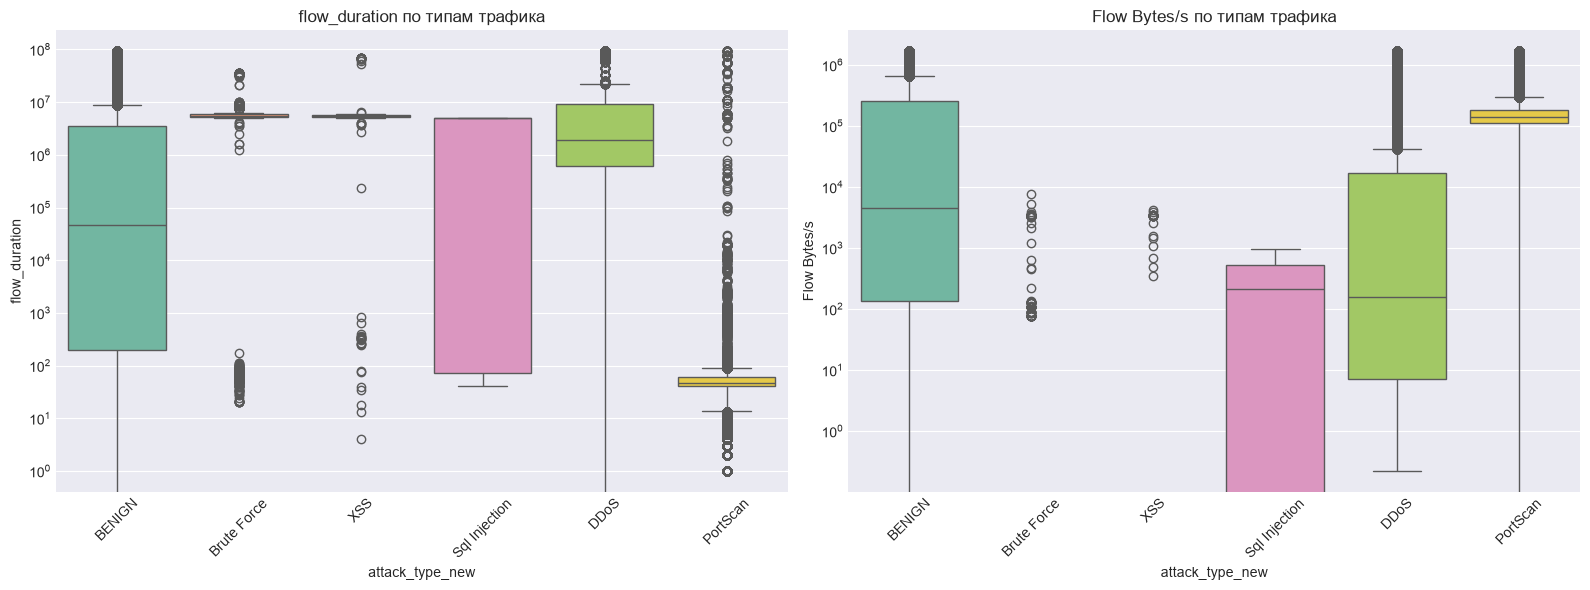

In [32]:
#4. Boxplot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=df, x='attack_type_new', y='flow_duration', 
    hue='attack_type_new', #Раскрасить по типу атаки
    palette='Set2', 
    legend=False, #Не показывать легенду
    ax=axes[0] #График слева
)
axes[0].set_yscale('log') #Логарифмическая шкала
axes[0].set_title('flow_duration по типам трафика')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(
    data=df, x='attack_type_new', y='Flow Bytes/s',hue='attack_type_new', 
    palette='Set2', legend=False, ax=axes[1]
)
axes[1].set_yscale('log')
axes[1].set_title('Flow Bytes/s по типам трафика')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

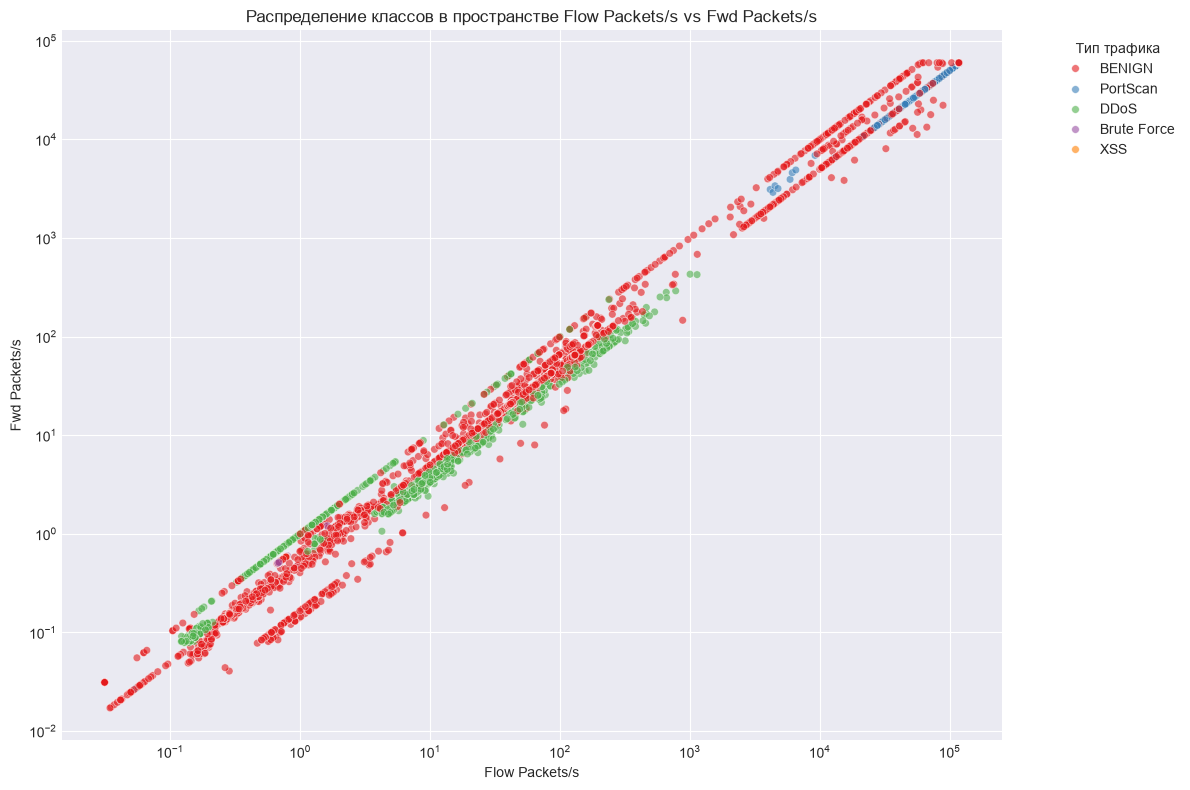

In [33]:
#5. Диаграмма рассеяния
plt.figure(figsize=(12, 8))

sample = df.sample(n=5000, random_state=0)

sns.scatterplot(
    data=sample,
    x='Flow Packets/s',
    y='Fwd Packets/s',
    hue='attack_type_new',
    palette='Set1',
    alpha=0.6,
    s=30
)
plt.xscale('log')
plt.yscale('log')
plt.title('Распределение классов в пространстве Flow Packets/s vs Fwd Packets/s')
plt.xlabel('Flow Packets/s')
plt.ylabel('Fwd Packets/s')
plt.legend(title='Тип трафика', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

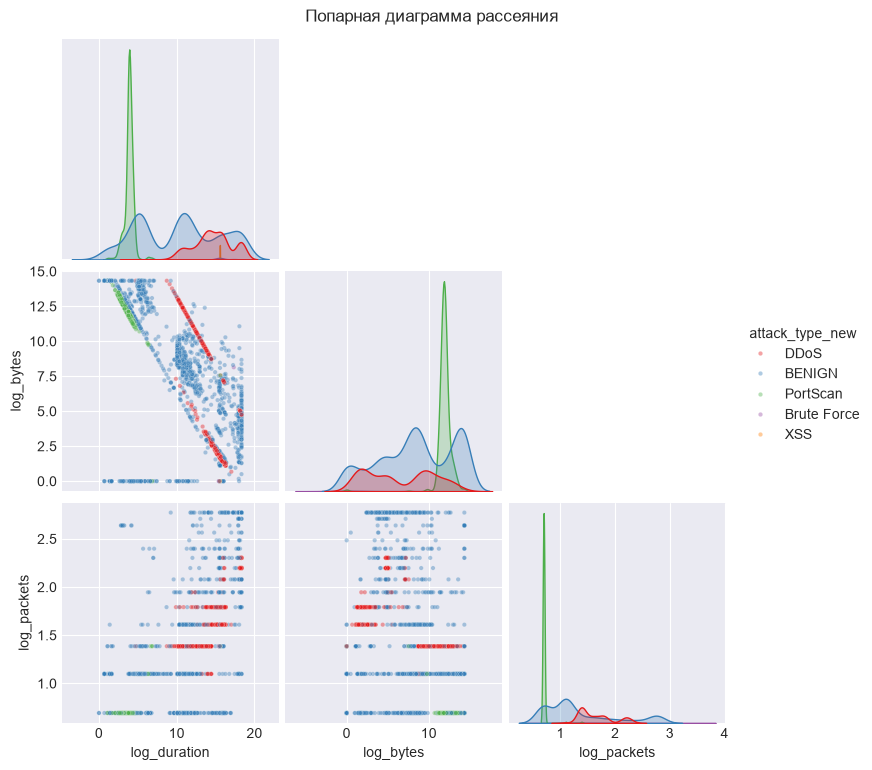

In [34]:
#6. Попарная диаграмма рассеяния
sample = df.sample(n=3000, random_state=42).copy() # Делаем независимую копию с выборкой
sample['log_duration'] = np.log1p(sample['flow_duration']) #Переводим в логарифмические значения для наглядности
sample['log_bytes'] = np.log1p(sample['Flow Bytes/s'])
sample['log_packets'] = np.log1p(sample['fwd_packets'])

sns.pairplot(
    sample[['log_duration', 'log_bytes', 'log_packets', 'attack_type_new']],
    hue='attack_type_new',
    palette='Set1',
    corner=True, #Убираем одинаковые симметричные диаграммы
    plot_kws={'alpha': 0.4, 's': 10}, #Прозрачность и размер точек
    diag_kind='kde' #Представление данных в виде непрерывной линии
)
plt.suptitle('Попарная диаграмма рассеяния', y=1.02)
plt.show()

In [35]:
# Нормализация: 
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)
X_test_scaled = scaler.transform(X_test_enc)

stats = pd.DataFrame({
    'feature': feature_names,
    'median': scaler.center_,
    'iqr': scaler.scale_
})
print(stats.head(20))

stats['normalized'] = (stats['median'] != 0) | (stats['iqr'] != 1)
print(f"\nПризнаки, где RobustScaler изменил данные: {stats['normalized'].sum()}")
print(stats[stats['normalized']].head(10))

                      feature   median        iqr
0          dst_port_top_other      0.0        1.0
1     dst_port_top_port_123.0      0.0        1.0
2     dst_port_top_port_137.0      0.0        1.0
3      dst_port_top_port_21.0      0.0        1.0
4      dst_port_top_port_22.0      0.0        1.0
5     dst_port_top_port_389.0      0.0        1.0
6     dst_port_top_port_443.0      0.0        1.0
7      dst_port_top_port_53.0      0.0        1.0
8   dst_port_top_port_55004.0      0.0        1.0
9      dst_port_top_port_80.0      0.0        1.0
10   dst_port_top_port_8080.0      0.0        1.0
11   dst_port_range_ephemeral      0.0        1.0
12  dst_port_range_registered      0.0        1.0
13  dst_port_range_well_known      1.0        1.0
14              flow_duration  30815.0  1869221.5
15                fwd_packets      2.0        3.0
16                bwd_packets      1.0        3.0
17          length_fwd_packet     26.0       76.0
18          length_bwd_packet     46.0      334.0


In [36]:
#Отбор признаков с низкой дисперсией
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01) #Отбор признаков, у которых дисперсия ниже порога. threshold = 0 значит удаляются признаки, 
                                            #у которых все значения одинаковые
X_train_var = selector.fit_transform(X_train_scaled) #fit() вычисляет эмпирические дисперсии на основе данных X_train_enc
#transform() озвращает новый массив, в котором удалены признаки с низкой дисперсией
X_test_var = selector.transform(X_test_scaled)

mask = selector.get_support() #какие признаки были убраны
removed = [feature_names[i1] for i1 in range(len(mask)) if not mask[i1]] #range(len(mask)) генерирует индексы всех элементов в маске
print("Удалены признаки (константы):", removed)
print(f"Осталось: {sum(mask)} из {len(mask)}")

print("X_train_var shape:", X_train_var.shape)
print("X_test_var shape: ", X_test_var.shape)

Удалены признаки (константы): ['dst_port_top_port_123.0', 'dst_port_top_port_137.0', 'dst_port_top_port_21.0', 'dst_port_top_port_22.0', 'dst_port_top_port_389.0', 'dst_port_top_port_8080.0', 'FIN Flag Count', 'RST Flag Count', 'ECE Flag Count']
Осталось: 81 из 90
X_train_var shape: (546031, 81)
X_test_var shape:  (136508, 81)


In [37]:
# Рекурсивное исключение признаков

from sklearn.feature_selection import RFE, RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

estimator = RandomForestClassifier(n_estimators=20, random_state=0, n_jobs=-1) #randomforest отбирает призначки по важности
#n_estimators - количество деревьев. Увеличение повышает точность
#step - сколько признаков удаляется за одну итерацию
rfe = RFE(estimator=estimator, n_features_to_select=15, step=5) #estimator - оценщик, информация о важности признаков

X_train_rfe = rfe.fit_transform(X_train_scaled, y_train_enc)
X_test_rfe = rfe.transform(X_test_scaled)

print(f"Train: {X_train_rfe.shape}, Test: {X_test_rfe.shape}")
assert X_train_rfe.shape[1] == X_test_rfe.shape[1]

selected_rfe = [feature_names[i3] for i3 in range(len(rfe.support_)) if rfe.support_[i3]]
print("RFE отобрал:", selected_rfe)

ranking = pd.DataFrame({'feature': feature_names, 'rank': rfe.ranking_}).sort_values('rank')
print(ranking)

rfecv = RFECV(estimator=estimator, step=5, cv=StratifiedKFold(n_splits=3), scoring='f1_weighted', n_jobs=-1) #Находим оптимальное число признаков
#(Recursive Feature Elimination with Cross-Validation
#cv задаёт стратегию кросс-валидации, разделяет данные на 3 части для обучения
#f1_weighted - метрика для оценки, учитывает неравновесность классов
#n_jobs=-1 - использование всех доступных CPU-ядер

X_train_rfecv = rfecv.fit_transform(X_train_scaled, y_train_enc)
X_test_rfecv  = rfecv.transform(X_test_scaled) 

assert X_train_rfe.shape[1] == X_test_rfe.shape[1]
assert X_train_rfecv.shape[1] == X_test_rfecv.shape[1]

print(f"Оптимальное количество признаков: {rfecv.n_features_}")

Train: (546031, 15), Test: (136508, 15)
RFE отобрал: ['dst_port_top_port_80.0', 'length_fwd_packet', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Packet Length Mean', 'Packet Length Std', 'Average Packet Size', 'Avg Fwd Segment Size', 'Subflow Fwd Bytes', 'total_bytes', 'bytes_ratio', 'packets_ratio', 'bytes_per_packet_fwd', 'bytes_diff', 'log_bytes_per_sec']
                      feature  rank
9      dst_port_top_port_80.0     1
25     Bwd Packet Length Mean     1
23      Bwd Packet Length Max     1
17          length_fwd_packet     1
51          Packet Length Std     1
50         Packet Length Mean     1
61        Average Packet Size     1
62       Avg Fwd Segment Size     1
87                 bytes_diff     1
82                bytes_ratio     1
81                total_bytes     1
84       bytes_per_packet_fwd     1
83              packets_ratio     1
89          log_bytes_per_sec     1
66          Subflow Fwd Bytes     1
24      Bwd Packet Length Min     2
71           act_da

In [38]:
# Одномерный отбор
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

selector1 = SelectKBest(score_func=f_classif, k=20) #Находит лучшие признаки, исходя из статистического теста
X_train_kbest = selector1.fit_transform(X_train_scaled, y_train_enc)
X_test_kbest = selector1.transform(X_test_scaled)

mask = selector1.get_support()
selected_features = [feature_names[i2] for i2 in range(len(mask)) if mask[i2]]
print("Топ-20 признаков:", selected_features)

scores = pd.DataFrame({
    'feature': feature_names,
    'score': selector1.scores_,
    'p_value': selector1.pvalues_ #Вероятность случайно получить связь между признаком и целевой переменной
}).sort_values('score', ascending=False)
print(scores.head(20))

print(f"X_train_kbest shape: {X_train_kbest.shape}")
print(f"X_test_kbest shape:  {X_test_kbest.shape}")
assert X_train_kbest.shape[1] == X_test_kbest.shape[1], "Размерности не совпадают"
print(f"Оба массива имеют {X_train_kbest.shape[1]} признаков")

Топ-20 признаков: ['dst_port_top_other', 'dst_port_top_port_80.0', 'dst_port_range_registered', 'dst_port_range_well_known', 'length_bwd_packet', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Bwd Packets/s', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'PSH Flag Count', 'Average Packet Size', 'Avg Bwd Segment Size', 'Subflow Bwd Bytes', 'total_bytes', 'bytes_per_packet_bwd', 'log_duration']
                      feature          score  p_value
9      dst_port_top_port_80.0  417721.933909      0.0
47              Bwd Packets/s  289347.555880      0.0
0          dst_port_top_other  282510.730543      0.0
12  dst_port_range_registered  207982.766492      0.0
26      Bwd Packet Length Std  189601.689392      0.0
25     Bwd Packet Length Mean  179712.322274      0.0
63       Avg Bwd Segment Size  179712.322274      0.0
85       bytes_per_packet_bwd  173216.580405      0.0
23      Bwd Packet Length Max  172257.261639

In [39]:
# Отбор по важности

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1) #Обучение randomforest
rf.fit(X_train_enc, y_train_enc) #Анализ данных и поиск закономерностей между параметрами и целевой переменной

importances = pd.DataFrame({'feature': feature_names, 'importance': rf.feature_importances_ }).sort_values('importance', ascending=False)
#Создаётся датафрейм, где сопоставляется признак и его важность, сортировка

print(importances.head(20))

threshold = 0.01
top_features = importances[importances['importance'] > threshold]['feature'].tolist() 
#Выбираются признаки, важность которых превышает порог
print(f"Оставлено {len(top_features)} признаков из {len(feature_names)}")

top_indices = [feature_names.index(f) for f in top_features] #Получение индексов отобранных признаков
X_train_top = X_train_enc[:, top_indices] #Оставляем только отобранные признаки
X_test_top = X_test_enc[:, top_indices]

                   feature  importance
19   Fwd Packet Length Max    0.065423
66       Subflow Fwd Bytes    0.057346
84    bytes_per_packet_fwd    0.054617
9   dst_port_top_port_80.0    0.050864
62    Avg Fwd Segment Size    0.044279
81             total_bytes    0.042275
21  Fwd Packet Length Mean    0.041539
17       length_fwd_packet    0.037440
61     Average Packet Size    0.036453
82             bytes_ratio    0.031582
63    Avg Bwd Segment Size    0.030890
88            log_duration    0.029280
26   Bwd Packet Length Std    0.028921
14           flow_duration    0.026467
50      Packet Length Mean    0.024361
23   Bwd Packet Length Max    0.023849
25  Bwd Packet Length Mean    0.021999
52  Packet Length Variance    0.020779
85    bytes_per_packet_bwd    0.020212
15             fwd_packets    0.017640
Оставлено 33 признаков из 90


In [40]:
#Обучение моделей
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay # Графическое представление матрицы ошибок для модели классификации

model_performance = pd.DataFrame(columns=['Accuracy','Recall','Precision','F1-Score','time to train','time to predict','total time'])

In [41]:
X_tr = X_train_top
X_te = X_test_top
y_tr = y_train_enc
y_te = y_test_enc

# К-ближайших соседей

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
import time

In [42]:
%%time
start = time.time() # Фиксируется момент времени перед обучением модели, чтобы посчитать длительность обучения
knn_model = KNeighborsClassifier(n_neighbors=3).fit(X_tr,y_tr) # обучаем модель
# Для классификации нового объекта модель будет смотреть на 3 ближайших соседа из обучающей выборки
end_train = time.time() # Фиксируется момент времени после обучением модели
y_predictions = knn_model.predict(X_te) # Предсказания на новых (тестовых) данных
end_predict = time.time() # Время после завершения предсказаний

CPU times: total: 5min 32s
Wall time: 55.8 s


In [43]:
accuracy = accuracy_score(y_te, y_predictions) # Точность модели
recall = recall_score(y_te, y_predictions, average='weighted') # Доля реальных положительных примеров
precision = precision_score(y_te, y_predictions, average='weighted') # Насколько точно модель предсказывает положительные случаи
f1s = f1_score(y_te, y_predictions, average='weighted') # F1-мера - среднее точности и полноты

# Вывод и сохранение результатов в датафрейм
print("Accuracy: "+ "{:.2%}".format(accuracy))
print("Recall: "+ "{:.2%}".format(recall))
print("Precision: "+ "{:.2%}".format(precision))
print("F1-Score: "+ "{:.2%}".format(f1s))
print("time to train: "+ "{:.2f}".format(end_train-start)+" s")
print("time to predict: "+"{:.2f}".format(end_predict-end_train)+" s")
print("total: "+"{:.2f}".format(end_predict-start)+" s")
model_performance.loc['kNN'] = [accuracy, recall, precision, f1s,end_train-start,end_predict-end_train,end_predict-start]

Accuracy: 98.42%
Recall: 98.42%
Precision: 98.44%
F1-Score: 98.43%
time to train: 0.07 s
time to predict: 55.75 s
total: 55.82 s


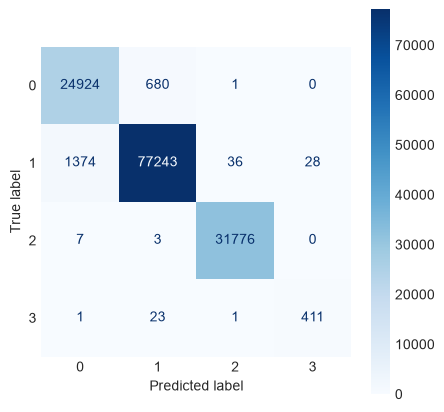

In [44]:
plt.rcParams['figure.figsize']=5,5 # Размер фигуры
sns.set_style("white") # Визуал
ConfusionMatrixDisplay.from_estimator(knn_model, X_te, y_te, cmap=plt.cm.Blues) # Построение матрицы ошибок
plt.show()

In [45]:
# Древо решений

In [46]:
%%time
from sklearn.tree import DecisionTreeClassifier
start = time.time()
dt_model = DecisionTreeClassifier().fit(X_tr,y_tr)
end_train = time.time()
y_predictions = dt_model.predict(X_te)
end_predict = time.time()

CPU times: total: 3.14 s
Wall time: 3.12 s


In [47]:
accuracy = accuracy_score(y_te, y_predictions)
recall = recall_score(y_te, y_predictions, average='weighted')
precision = precision_score(y_te, y_predictions, average='weighted')
f1s = f1_score(y_te, y_predictions, average='weighted')

print("Accuracy: "+ "{:.2%}".format(accuracy))
print("Recall: "+ "{:.2%}".format(recall))
print("Precision: "+ "{:.2%}".format(precision))
print("F1-Score: "+ "{:.2%}".format(f1s))
print("time to train: "+ "{:.2f}".format(end_train-start)+" s")
print("time to predict: "+"{:.2f}".format(end_predict-end_train)+" s")
print("total: "+"{:.2f}".format(end_predict-start)+" s")
model_performance.loc['Decision Tree'] = [accuracy, recall, precision, f1s,end_train-start,end_predict-end_train,end_predict-start]

Accuracy: 99.96%
Recall: 99.96%
Precision: 99.96%
F1-Score: 99.96%
time to train: 3.11 s
time to predict: 0.01 s
total: 3.12 s


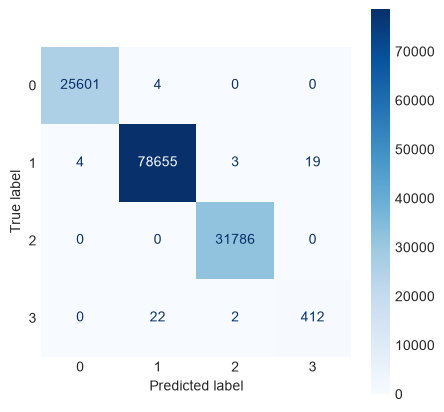

In [48]:
plt.rcParams['figure.figsize']=5,5 
sns.set_style("white")
ConfusionMatrixDisplay.from_estimator(dt_model, X_te, y_te, cmap=plt.cm.Blues)  
plt.show()

In [49]:
# Случайный лес

In [50]:
%%time
from sklearn.ensemble import RandomForestClassifier
start = time.time()
rf_model = RandomForestClassifier(n_estimators = 100,n_jobs=-1,random_state=0,bootstrap=True,).fit(X_tr,y_tr)
end_train = time.time()
y_predictions = rf_model.predict(X_te)
end_predict = time.time()

CPU times: total: 1min 34s
Wall time: 8.61 s


In [51]:
accuracy = accuracy_score(y_te, y_predictions)
recall = recall_score(y_te, y_predictions, average='weighted')
precision = precision_score(y_te, y_predictions, average='weighted')
f1s = f1_score(y_te, y_predictions, average='weighted')

print("Accuracy: "+ "{:.2%}".format(accuracy))
print("Recall: "+ "{:.2%}".format(recall))
print("Precision: "+ "{:.2%}".format(precision))
print("F1-Score: "+ "{:.2%}".format(f1s))
print("time to train: "+ "{:.2f}".format(end_train-start)+" s")
print("time to predict: "+"{:.2f}".format(end_predict-end_train)+" s")
print("total: "+"{:.2f}".format(end_predict-start)+" s")
model_performance.loc['Random Forest'] = [accuracy, recall, precision, f1s,end_train-start,end_predict-end_train,end_predict-start]

Accuracy: 99.98%
Recall: 99.98%
Precision: 99.98%
F1-Score: 99.98%
time to train: 8.53 s
time to predict: 0.08 s
total: 8.61 s


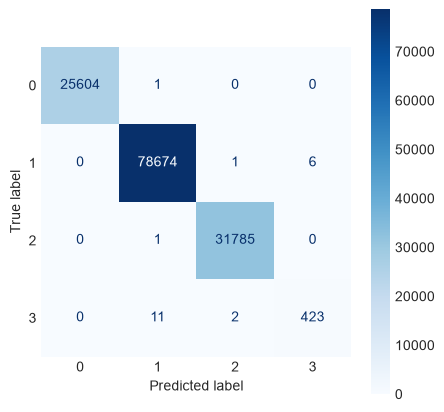

In [52]:
plt.rcParams['figure.figsize']=5,5 
sns.set_style("white")
ConfusionMatrixDisplay.from_estimator(rf_model, X_te, y_te, cmap=plt.cm.Blues)  
plt.show()

In [53]:
# Градиентный бустинг

In [55]:
%%time
from catboost import CatBoostClassifier
start = time.time()
cat_model = CatBoostClassifier(
    iterations=500, # Число итераций (деревьев), чем больше итераций, тем выше точность
    learning_rate=0.1, # Размер шага, меньшее значение снижает риск переобучения
    depth=6, # Глубина деревьев
    loss_function='MultiClass', # Для многоклассовой классификации
    eval_metric='TotalF1', # Метрика для валидации. TotalF1 - метрика, которая учитывает точность, recall для каждого класса
    class_weights=None, # Веса не заданы, библиотека сама попробует найти баланс         
    random_seed=0,
    verbose=100, # Выводить прогресс каждые 100 итераций
    thread_count=-1 # Использовать все ядра
).fit(X_tr,y_tr)
end_train = time.time()
y_predictions = cat_model.predict(X_te)
end_predict = time.time()

0:	learn: 0.9915272	total: 90.4ms	remaining: 45.1s
100:	learn: 0.9981125	total: 7.86s	remaining: 31s
200:	learn: 0.9983836	total: 14.8s	remaining: 22s
300:	learn: 0.9984526	total: 21.6s	remaining: 14.3s
400:	learn: 0.9984656	total: 28.4s	remaining: 7.02s
499:	learn: 0.9984722	total: 35.2s	remaining: 0us
CPU times: total: 6min 28s
Wall time: 35.5 s


In [56]:
accuracy = accuracy_score(y_te, y_predictions)
recall = recall_score(y_te, y_predictions, average='weighted')
precision = precision_score(y_te, y_predictions, average='weighted')
f1s = f1_score(y_te, y_predictions, average='weighted')

print("Accuracy: "+ "{:.2%}".format(accuracy))
print("Recall: "+ "{:.2%}".format(recall))
print("Precision: "+ "{:.2%}".format(precision))
print("F1-Score: "+ "{:.2%}".format(f1s))
print("time to train: "+ "{:.2f}".format(end_train-start)+" s")
print("time to predict: "+"{:.2f}".format(end_predict-end_train)+" s")
print("total: "+"{:.2f}".format(end_predict-start)+" s")
model_performance.loc['Gradient Boosting Classifier'] = [accuracy, recall, precision, f1s,end_train-start,end_predict-end_train,end_predict-start]

Accuracy: 99.83%
Recall: 99.83%
Precision: 99.85%
F1-Score: 99.84%
time to train: 35.43 s
time to predict: 0.05 s
total: 35.48 s


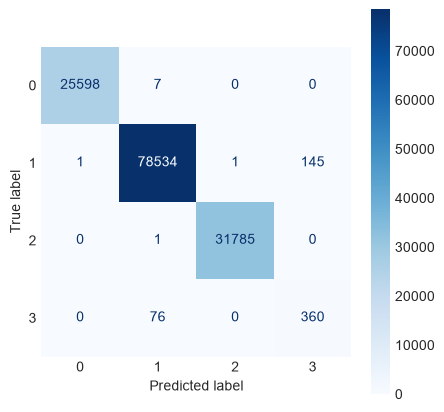

In [57]:
plt.rcParams['figure.figsize']=5,5 
sns.set_style("white")
ConfusionMatrixDisplay.from_estimator(cat_model, X_te, y_te, cmap=plt.cm.Blues)  
plt.show()

In [59]:
# Нейронные сети

In [60]:
%%time
from sklearn.neural_network import MLPClassifier
start = time.time()
nn_model = MLPClassifier(hidden_layer_sizes = (20,20,), # Архитектура сети, сколько слоёв и сколько нейронов
                      activation='relu', # Возвращает входное значение, если оно положительное, и ноль, если отрицательное
                      solver='adam', # Подбор шага обучения для каждого веса
                      batch_size=2000, # Сколько примеров из обучающей выборки используется за один шаг обновления весов
                      verbose=0).fit(X_tr,y_tr) # Не выводит прогресс
end_train = time.time()
y_predictions = nn_model.predict(X_te)
end_predict = time.time()

CPU times: total: 45.8 s
Wall time: 41.5 s


In [61]:
accuracy = accuracy_score(y_te, y_predictions)
recall = recall_score(y_te, y_predictions, average='weighted')
precision = precision_score(y_te, y_predictions, average='weighted')
f1s = f1_score(y_te, y_predictions, average='weighted')

print("Accuracy: "+ "{:.2%}".format(accuracy))
print("Recall: "+ "{:.2%}".format(recall))
print("Precision: "+ "{:.2%}".format(precision))
print("F1-Score: "+ "{:.2%}".format(f1s))
print("time to train: "+ "{:.2f}".format(end_train-start)+" s")
print("time to predict: "+"{:.2f}".format(end_predict-end_train)+" s")
print("total: "+"{:.2f}".format(end_predict-start)+" s")
model_performance.loc['MLP'] = [accuracy, recall, precision, f1s,end_train-start,end_predict-end_train,end_predict-start]

Accuracy: 90.41%
Recall: 90.41%
Precision: 92.16%
F1-Score: 90.57%
time to train: 41.45 s
time to predict: 0.03 s
total: 41.48 s


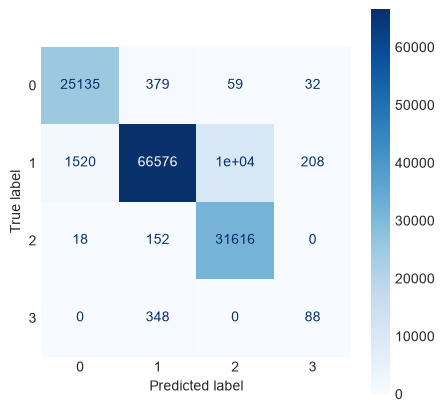

In [62]:
plt.rcParams['figure.figsize']=5,5 
sns.set_style("white")
ConfusionMatrixDisplay.from_estimator(nn_model, X_te, y_te, cmap=plt.cm.Blues)  
plt.show()

In [63]:
model_performance.style.background_gradient(cmap='coolwarm').format({'Accuracy': '{:.2%}',
                                                                     'Precision': '{:.2%}',
                                                                     'Recall': '{:.2%}',
                                                                     'F1-Score': '{:.2%}',
                                                                     'time to train':'{:.1f}',
                                                                     'time to predict':'{:.1f}',
                                                                     'total time':'{:.1f}',
                                                                     })

,Accuracy,Recall,Precision,F1-Score,time to train,time to predict,total time
kNN,98.42%,98.42%,98.44%,98.43%,0.1,55.7,55.8
Decision Tree,99.96%,99.96%,99.96%,99.96%,3.1,0.0,3.1
Random Forest,99.98%,99.98%,99.98%,99.98%,8.5,0.1,8.6
Gradient Boosting Classifier,99.83%,99.83%,99.85%,99.84%,35.4,0.0,35.5
MLP,90.41%,90.41%,92.16%,90.57%,41.4,0.0,41.5


In [ ]:
# Ищем параметры, которые наиболее сильно влияют на процесс обучения

In [ ]:
from sklearn.base import clone

# Функция для исследования параметров
def explore_parameters(model, param_name, param_values, X_tr, y_tr, X_te, y_te, sample_size=None):

    results = []
    
    if sample_size is not None and len(X_tr) > sample_size: # Подвыборка
        from sklearn.model_selection import train_test_split
        X_tr_s, _, y_tr_s, _ = train_test_split(
            X_tr, y_tr, train_size=sample_size, random_state=0, stratify=y_tr
        )
    else:
        X_tr_s, y_tr_s = X_tr, y_tr
    
    for val in param_values:

        m = clone(model)
        m.set_params(**{param_name: val})
        
        t0 = time.time()
        m.fit(X_tr_s, y_tr_s)
        train_time = time.time() - t0
        
        y_pred = m.predict(X_te)
        
        results.append({
            param_name: val,
            'F1-weighted': f1_score(y_te, y_pred, average='weighted'),
            'F1-macro': f1_score(y_te, y_pred, average='macro'),
            'Accuracy': accuracy_score(y_te, y_pred),
            'Train time (s)': round(train_time, 2)
        })
        
        print(f"  {param_name}={val}: F1={results[-1]['F1-weighted']:.4f}, time={train_time:.1f}s")
    
    return pd.DataFrame(results)

In [ ]:
# K ближайших соседей

knn_base = KNeighborsClassifier(n_jobs=-1)

# n_neighbors
res_knn_n = explore_parameters(knn_base, 'n_neighbors', [1, 3, 5, 7, 11, 15, 21, 31], X_tr, y_tr, X_te, y_te, sample_size=20000)
print("\nKNN — влияние n_neighbors:")
print(res_knn_n.to_string(index=False))
'''
n_neighbors - количество ближайших соседей, используемых для классификации. 
Это объекты из обучающей выборки, которые находятся ближе всего к новому, тестовому объекту. 
Объекты, расположенные близко друг к другу в пространстве признаков, с высокой вероятностью принадлежат к одному классу.
Из всех точек выбираются те, у которых расстояние до тестового объекта наименьшее.
При малом количестве соседей предсказание будет сильно зависеть от одной ближайшей точки.
При слишком большом количестве алгоритм игнорирует локальные особенности данных.
'''

# weights
res_knn_w = explore_parameters(knn_base, 'weights', ['uniform', 'distance'], X_tr, y_tr, X_te, y_te, sample_size=20000)
print("\nKNN — влияние weights:")
print(res_knn_w.to_string(index=False))
'''
weights - параметр определяет, как будут учитываться веса соседей при голосовании за класс. 
uniform - все соседи получают одинаковый вес, независимо от расстояния до новой точки. Это классический вариант метода k-NN.
distance - вес каждого соседа обратно пропорционален расстоянию до новой точки. Ближайшие соседи оказывают большее влияние на предсказание, чем далёкие.
Callable или None - принимает массив расстояний и возвращает массив весов той же формы.
'''

In [ ]:
# Дерево решений 
dt_base = DecisionTreeClassifier(random_state=0, class_weight='balanced')

# max_depth
res_dt = explore_parameters(dt_base, 'max_depth', [3, 5, 7, 10, 15, 20, None], X_tr, y_tr, X_te, y_te)
print("\nDT — влияние max_depth:")
print(res_dt.to_string(index=False))
'''
max_depth - максимальное расстояние от корня до любого листа.
Без ограничения дерево может стать слишком сложным.
'''

# min_samples_leaf
res_dt_leaf = explore_parameters(dt_base, 'min_samples_leaf', [1, 5, 10, 20, 50, 100], X_tr, y_tr, X_te, y_te)
print("\nDT — влияние min_samples_leaf:")
print(res_dt_leaf.to_string(index=False))
'''
min_samples_leaf - определяет, сколько образцов должно находиться в каждом листовом узле.
Гарантирует, что каждый лист представляет достаточно репрезентативное подмножество данных
'''

In [ ]:
# Случайный лес

rf_base = RandomForestClassifier(random_state=0, class_weight='balanced', n_jobs=-1)

# n_estimators
res_rf = explore_parameters(rf_base, 'n_estimators', [10, 30, 50, 100, 200, 300], X_tr, y_tr, X_te, y_te)
print("\nRF — влияние n_estimators:")
print(res_rf.to_string(index=False))
'''
n_estimators - количество деревьев, которые составляют «лес».
Алгоритм строит сразу несколько решающих деревьев, а потом их результаты усредняются.
Чем больше деревьев в лесу, тем точнее и стабильнее модель.
'''
# max_depth
res_rf_depth = explore_parameters(rf_base, 'max_depth', [5, 10, 15, 20, 30, None], X_tr, y_tr, X_te, y_te)
print("\nRF — влияние max_depth:")
print(res_rf_depth.to_string(index=False))
'''
max_depth - определяет максимальную глубину каждого отдельного дерева в лесу. 
Задаёт, сколько уровней будет в каждом дереве решений. 
Неглубокие деревья менее чувствительны к шуму в данных, но могут упустить сложные зависимости.
Чем значение больше, тем сложнее модель, она лучше подстраивается под обучающие данные, но возрастает риск переобучения на тестовой выборке.
'''

In [ ]:
# Градиентный бустинг

cat_base = CatBoostClassifier(random_seed=0, verbose=0, thread_count=-1, loss_function='MultiClass')

# iterations
res_cat = explore_parameters(cat_base, 'iterations', [50, 100, 200, 300, 500], X_tr, y_tr, X_te, y_te)
print("\nCatBoost — влияние iterations:")
print(res_cat.to_string(index=False))
'''
iterations
'''
# learning_rate
res_cat_lr = explore_parameters(cat_base, 'learning_rate', [0.01, 0.03, 0.05, 0.1, 0.2], X_tr, y_tr, X_te, y_te)
print("\nCatBoost — влияние learning_rate:")
print(res_cat_lr.to_string(index=False))
'''
learning_rate
'''
# depth
res_cat_depth = explore_parameters(cat_base, 'depth', [3, 4, 6, 8, 10], X_tr, y_tr, X_te, y_te)
print("\nCatBoost — влияние depth:")
print(res_cat_depth.to_string(index=False))
'''
depth
''' 